In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

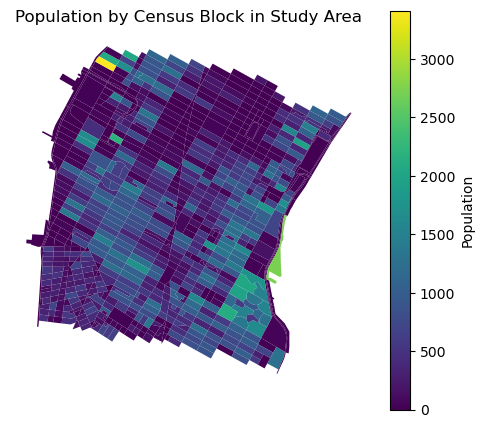

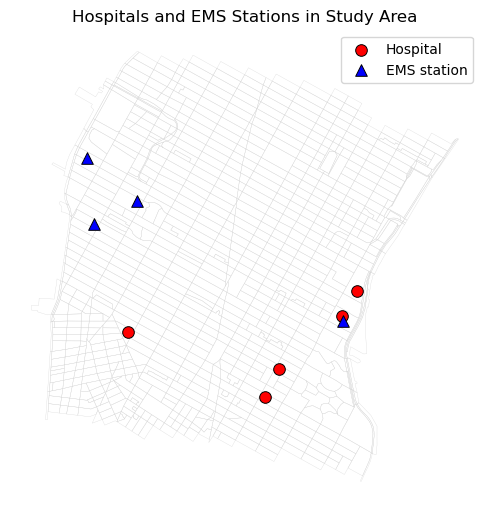

In [2]:
# ---------------------------------------------------------------------
# Load the GeoPackage outputs
# ---------------------------------------------------------------------

population = gpd.read_file("manhattan-data/manhattan_population_blocks.gpkg")
facilities = gpd.read_file("manhattan-data/manhattan_hospitals_ems.gpkg")


# ---------------------------------------------------------------------
# Population map
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 6))

population.plot(
    ax=ax,
    column="POP20",
    cmap="viridis",
    linewidth=0,
    legend=True,
    legend_kwds={
        "label": "Population",
        "shrink": 0.7,
    },
)

ax.set_title("Population by Census Block in Study Area")
ax.set_axis_off()

plt.tight_layout()
plt.show()


# ---------------------------------------------------------------------
# Hospitals and EMS stations
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 6))

# Plot a light population/block geography as the background
population.plot(
    ax=ax,
    facecolor="none",
    edgecolor="lightgray",
    linewidth=0.2,
)

# Separate the two facility types
hospitals = facilities[
    facilities["asset_type"].str.lower() == "hospital"
]

ems = facilities[
    facilities["asset_type"].str.lower() == "ems station"
]

# Plot hospitals
hospitals.plot(
    ax=ax,
    marker="o",
    markersize=70,
    color="red",
    edgecolor="black",
    linewidth=0.7,
    label="Hospital",
)

# Plot EMS stations
ems.plot(
    ax=ax,
    marker="^",
    markersize=70,
    color="blue",
    edgecolor="black",
    linewidth=0.7,
    label="EMS station",
)

ax.set_title("Hospitals and EMS Stations in Study Area")
ax.legend()
ax.set_axis_off()

plt.tight_layout()
plt.show()



In [3]:
from utils import generate_incidents
incidents = generate_incidents(
    population,
    n_days=10,
    rate_per_1000_per_day=0.1,
    random_seed=42,
)
print(len(incidents))
incidents.head()

348


,day,seconds_since_midnight,hour,minute,second,block_index,latitude,longitude,geometry
0,0,409.656348,0,6,49,734,40.745712,-73.992617,POINT (-73.99262 40.74571)
1,0,800.045149,0,13,20,522,40.752141,-73.998314,POINT (-73.99831 40.75214)
2,0,2702.895515,0,45,2,548,40.748447,-73.998202,POINT (-73.9982 40.74845)
3,0,4093.115328,1,8,13,464,40.745560,-74.000148,POINT (-74.00015 40.74556)
4,0,4196.386643,1,9,56,352,40.754691,-73.967109,POINT (-73.96711 40.75469)


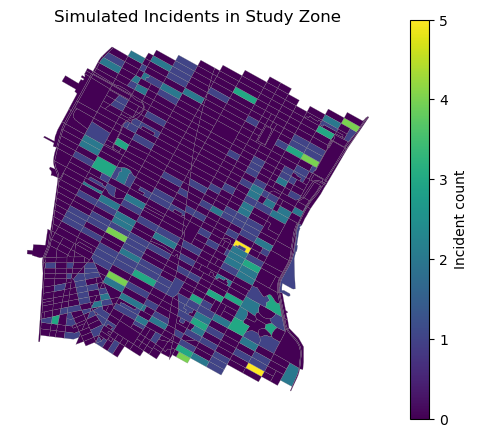

In [4]:
# Count incidents in each Census block
counts = (
    incidents
    .groupby("block_index")
    .size()
    .rename("incident_count")
)


# Join counts back to Census blocks
population["incident_count"] = (
    population.index.to_series()
    .map(counts)
    .fillna(0)
    .astype(int)
)


# Plot
fig, ax = plt.subplots(figsize=(5, 6))

population.plot(
    ax=ax,
    column="incident_count",
    cmap="viridis",
    linewidth=0.15,
    edgecolor="gray",
    legend=True,
    legend_kwds={
        "label": "Incident count",
        "shrink": 0.7,
    },
)

ax.set_title(
    "Simulated Incidents in Study Zone"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()